In [2]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 3.4 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/11.3 MB 8.8 MB/s eta 0:00:01
   -------------- ------------------------- 4.2/11.3 MB 9.7 MB/s eta 0:00:01
   -------------------- ------------------- 5.8/11.3 MB 7.5 MB/s eta 0:00:01
   ---------------------------- ----------- 8.1/11.3 MB 8.4 MB/s eta 0:00:01
   -------------------------------------- - 10.7/11.3 MB 9.1 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 9.1 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 9.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 6.7 MB/s  0:00:01

   ------ --------------------------------- 1/6 [patsy]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
   ------------- -------------------------- 2/6 [narwhals]
  


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("statsmodels успішно встановлено")

statsmodels успішно встановлено


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import probplot, shapiro

np.random.seed(42)

city = "Київ"
mean_temp = 9.5
amplitude = 14
hum_base = 74

rows = []

for month in range(1, 13):
    temp = (
        mean_temp
        + amplitude * np.cos((month - 7) / 12 * 2 * np.pi)
        + np.random.normal(0, 1.0)
    )

    humidity = hum_base + np.random.normal(0, 5.0)

    if temp < 8:
        opal_days = 30
    elif temp < 12:
        opal_days = 15
    else:
        opal_days = 0

    cost = (
        200
        - 9.0 * temp
        + 0.6 * humidity
        + 2.5 * opal_days
        + np.random.normal(0, 15)
    )

    rows.append({
        "місто": city,
        "місяць": month,
        "температура": round(temp, 1),
        "вологість": round(humidity, 1),
        "опалювальні_дні": opal_days,
        "витрати_на_опалення": round(cost, 1),
    })

heating = pd.DataFrame(rows)

display(heating)

,місто,місяць,температура,вологість,опалювальні_дні,витрати_на_опалення
0,Київ,1,-4.0,73.3,30,364.7
1,Київ,2,-1.1,72.8,30,325.1
2,Київ,3,4.1,77.8,30,277.9
3,Київ,4,10.0,71.7,15,183.1
4,Київ,5,16.7,64.4,0,62.1
5,Київ,6,21.1,68.9,0,56.5
6,Київ,7,22.6,66.9,0,58.8
7,Київ,8,21.4,74.3,0,30.6
8,Київ,9,16.0,74.6,0,83.9
9,Київ,10,9.9,71.0,15,186.8


In [6]:
X2 = heating[["температура", "вологість"]]
X2 = sm.add_constant(X2)
y = heating["витрати_на_опалення"]

model2 = sm.OLS(y, X2).fit()

print(model2.summary())
print(f"\nR² = {model2.rsquared:.4f}")
print(f"Adjusted R² = {model2.rsquared_adj:.4f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.976
Model:                             OLS   Adj. R-squared:                  0.970
Method:                  Least Squares   F-statistic:                     179.6
Date:                 Thu, 15 Oct 2026   Prob (F-statistic):           5.58e-08
Time:                         21:03:24   Log-Likelihood:                -52.453
No. Observations:                   12   AIC:                             110.9
Df Residuals:                        9   BIC:                             112.4
Df Model:                            2                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         223.1684    122.718      1

In [7]:
for name in ["температура", "вологість"]:
    coef = model2.params[name]
    p_value = model2.pvalues[name]

    print(f"\nПредиктор: {name}")
    print(f"Коефіцієнт: {coef:.4f}")
    print(f"p-value: {p_value:.4f}")

    if p_value < 0.05:
        print("Предиктор статистично значущий при alpha = 0.05.")
    else:
        print("Немає достатніх підстав вважати предиктор статистично значущим при alpha = 0.05.")


Предиктор: температура
Коефіцієнт: -12.2829
p-value: 0.0000
Предиктор статистично значущий при alpha = 0.05.

Предиктор: вологість
Коефіцієнт: 1.1483
p-value: 0.4936
Немає достатніх підстав вважати предиктор статистично значущим при alpha = 0.05.


In [8]:
X_vif2 = heating[["температура", "вологість"]]

vif2 = pd.DataFrame({
    "Предиктор": X_vif2.columns,
    "VIF": [
        variance_inflation_factor(X_vif2.values, i)
        for i in range(X_vif2.shape[1])
    ]
})

display(vif2)

,Предиктор,VIF
0,температура,1.55295
1,вологість,1.55295


**Інтерпретація коефіцієнтів моделі**

За інших рівних умов збільшення температури на 1 °C пов’язане зі зменшенням витрат на опалення в середньому на 12,2829 одиниці. Температура є статистично значущим предиктором, оскільки p-value < 0,001 < 0,05.

За інших рівних умов збільшення відносної вологості на 1 відсотковий пункт пов’язане зі збільшенням витрат на опалення в середньому на 1,1483 одиниці. Проте вологість не є статистично значущим предиктором, оскільки p-value = 0,494 > 0,05.

Коефіцієнт детермінації R² = 0,9756 означає, що модель пояснює приблизно 97,56% варіації витрат на опалення. Скоригований R² = 0,9701 враховує кількість предикторів у моделі.

In [9]:
X3 = heating[["температура", "вологість", "опалювальні_дні"]]
X3 = sm.add_constant(X3)

model3 = sm.OLS(y, X3).fit()

print(model3.summary())
print(f"\nМодель 2 — R²: {model2.rsquared:.4f}")
print(f"Модель 2 — Adjusted R²: {model2.rsquared_adj:.4f}")
print(f"Модель 3 — R²: {model3.rsquared:.4f}")
print(f"Модель 3 — Adjusted R²: {model3.rsquared_adj:.4f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.992
Model:                             OLS   Adj. R-squared:                  0.988
Method:                  Least Squares   F-statistic:                     314.0
Date:                 Thu, 15 Oct 2026   Prob (F-statistic):           1.23e-08
Time:                         21:05:45   Log-Likelihood:                -46.060
No. Observations:                   12   AIC:                             100.1
Df Residuals:                        8   BIC:                             102.1
Df Model:                            3                                         
Covariance Type:             nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             237.4012     7

**Порівняння моделей**

Після додавання предиктора «опалювальні дні» коефіцієнт детермінації збільшився з 0,9756 до 0,9916, а скоригований коефіцієнт детермінації — з 0,9701 до 0,9884. Отже, третій предиктор покращив пояснювальну здатність моделі навіть з урахуванням штрафу за збільшення кількості предикторів.

У третій моделі температура є статистично значущою (p-value = 0,002), кількість опалювальних днів також статистично значуща (p-value = 0,005), а вологість не є статистично значущою (p-value = 0,548). Додавання кількості опалювальних днів є доцільним, оскільки скоригований R² зріс. Водночас слід перевірити VIF, адже кількість опалювальних днів залежить від температури.

**Перевірка мультиколінеарності**

Значення VIF для температури та вологості становить приблизно 1,553 для кожного предиктора. Оскільки ці значення менші за 5, суттєвої мультиколінеарності не виявлено. Це означає, що взаємозв’язок між предикторами не створює значних проблем для оцінювання коефіцієнтів моделі.

In [11]:
X_vif3 = heating[["температура", "вологість", "опалювальні_дні"]]

vif3 = pd.DataFrame({
    "Предиктор": X_vif3.columns,
    "VIF": [
        variance_inflation_factor(X_vif3.values, i)
        for i in range(X_vif3.shape[1])
    ]
})

display(vif3)

,Предиктор,VIF
0,температура,13.409621
1,вологість,1.898510
2,опалювальні_дні,15.617899


**Аналіз VIF третьої моделі**

Для температури VIF = 13,41, а для кількості опалювальних днів VIF = 15,62. Обидва значення перевищують 10, що свідчить про сильну мультиколінеарність. Це пояснюється тим, що кількість опалювальних днів визначається залежно від температури. Такий взаємозв’язок може робити оцінки окремих коефіцієнтів нестабільними. Для практичного застосування моделі варто розглянути вилучення одного з цих предикторів. Для вологості VIF = 1,90, тому суттєвої мультиколінеарності не виявлено.

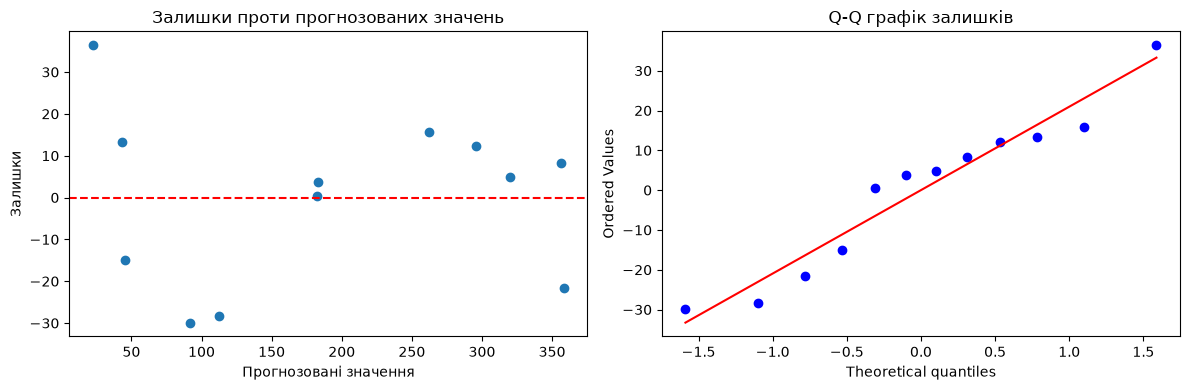

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(model2.fittedvalues, model2.resid)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Прогнозовані значення")
axes[0].set_ylabel("Залишки")
axes[0].set_title("Залишки проти прогнозованих значень")

probplot(model2.resid, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q графік залишків")

plt.tight_layout()
plt.show()

In [13]:
stat, p_value = shapiro(model2.resid)

print(f"Статистика Шапіро — Вілка: {stat:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value > 0.05:
    print("Немає достатніх підстав відхиляти гіпотезу про нормальність залишків.")
else:
    print("Гіпотеза про нормальність залишків відхиляється при alpha = 0.05.")

Статистика Шапіро — Вілка: 0.9388
p-value: 0.4828
Немає достатніх підстав відхиляти гіпотезу про нормальність залишків.


**Аналіз залишків моделі**

На графіку залишків проти прогнозованих значень можна оцінити наявність закономірностей і неоднакової дисперсії залишків. Q-Q графік дає змогу візуально оцінити їхню відповідність нормальному розподілу. За результатами тесту Шапіро — Вілка статистика становить 0,9388, а p-value = 0,4828. Оскільки p-value > 0,05, немає достатніх підстав відхиляти гіпотезу про нормальність залишків на рівні значущості 0,05.

In [14]:
X1 = heating[["температура"]]
X1 = sm.add_constant(X1)

model1 = sm.OLS(y, X1).fit()

print(model1.summary())
print(f"\nПроста модель — R²: {model1.rsquared:.4f}")
print(f"Модель із двома предикторами — R²: {model2.rsquared:.4f}")
print(f"Модель із двома предикторами — Adjusted R²: {model2.rsquared_adj:.4f}")

                             OLS Regression Results                            
Dep. Variable:     витрати_на_опалення   R-squared:                       0.974
Model:                             OLS   Adj. R-squared:                  0.972
Method:                  Least Squares   F-statistic:                     377.2
Date:                 Thu, 15 Oct 2026   Prob (F-statistic):           2.86e-09
Time:                         22:18:16   Log-Likelihood:                -52.784
No. Observations:                   12   AIC:                             109.6
Df Residuals:                       10   BIC:                             110.5
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         310.4901      8.806     35

**Порівняння простої та множинної регресії**

У простій моделі, яка використовує лише температуру, R² = 0,9742. У моделі з температурою та вологістю R² = 0,9756, а скоригований R² = 0,9701. Додавання вологості дещо збільшило R², але скоригований R² множинної моделі виявився нижчим за R² простої моделі. Це свідчить про те, що додавання вологості не забезпечило достатнього покращення з урахуванням кількості предикторів. Звичайний R² не зменшується при додаванні предикторів, оскільки модель може залишити коефіцієнт нового предиктора рівним нулю.

**Контрольні питання**

**1. Для чого потрібен `sm.add_constant()` перед OLS? Що станеться, якщо його не додати?**

Функція `sm.add_constant()` додає до матриці предикторів стовпець одиниць, який дає змогу оцінити вільний член моделі. Якщо не додати константу, модель зазвичай оцінюватиметься без вільного члена, тобто буде примусово проходити через початок координат. Це може призвести до некоректних оцінок коефіцієнтів.

**2. Чим коефіцієнт множинної регресії відрізняється від коефіцієнта простої регресії для того самого предиктора?**

У простій регресії коефіцієнт відображає зв’язок між предиктором і залежною змінною без урахування інших предикторів. У множинній регресії він показує очікувану зміну залежної змінної при збільшенні відповідного предиктора на одну одиницю за незмінних значень інших предикторів.

**3. Чому звичайний R² не зменшується при додаванні предикторів і чому ним не варто порівнювати моделі з різною кількістю предикторів?**

Додавання предиктора не звужує можливості моделі, оскільки його коефіцієнт може дорівнювати нулю. Тому R² або збільшується, або залишається незмінним. Для порівняння моделей із різною кількістю предикторів доцільно використовувати скоригований R², який враховує кількість предикторів і може зменшуватися, якщо нові змінні не покращують модель достатньо.

**4. Що означає VIF ≈ 1 і VIF > 10? Що робити на практиці?**

VIF ≈ 1 означає, що предиктор майже не має лінійного зв’язку з іншими предикторами. VIF > 10 вказує на сильну мультиколінеарність, яка може робити оцінки коефіцієнтів нестабільними. На практиці варто перевірити взаємозв’язки між предикторами, обґрунтовано вилучити один із сильно пов’язаних предикторів або змінити специфікацію моделі, не втрачаючи важливої інформації.